# 05 · Advanced GNNs — Attention, Expressiveness, Honest Evaluation, Explainability

**GNNs for Medicine — Lesson 5 of 5**

With the mechanics understood (Track 1) and the library in hand (NB04), we reach the ideas that separate a toy GNN from one you'd trust in drug discovery:

- **A — Better layers:** **GAT** (attention) and **GIN** (maximum expressiveness).
- **B — Honest evaluation:** **scaffold splitting** — why your random-split AUC is optimistic.
- **C — Explainability:** **GNNExplainer** — *which atoms* drove a prediction.
- **D — Where to go next:** edge features, 3D geometry, pretraining, other medical graphs.

In [1]:
!pip install -q torch-geometric rdkit

In [2]:
import warnings; warnings.filterwarnings('ignore')
import torch, numpy as np, torch.nn.functional as F
from collections import defaultdict
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GATConv, GINConv, global_mean_pool
from sklearn.metrics import roc_auc_score
from rdkit import Chem, RDLogger; RDLogger.DisableLog('rdApp.*')
torch.manual_seed(0); np.random.seed(0)

dataset = MoleculeNet(root='data/MoleculeNet', name='BBBP')
NF = dataset.num_node_features
print(len(dataset), 'molecules |', NF, 'node features')

2039 molecules | 9 node features


## A. Beyond GCN: GAT and GIN

**GCN** weights every neighbour by a *fixed* factor from node degrees (NB02). Two ideas improve on that:

**GAT — Graph Attention Network.** Instead of fixed weights, the model *learns* how much attention each neighbour deserves, with attention coefficients computed from the node features themselves. A nitrogen next to a carbonyl can matter more than a distant carbon — GAT can learn that. Multiple attention "heads" run in parallel for stability.

**GIN — Graph Isomorphism Network.** Theory (Xu et al., 2019) shows most GNNs can't tell apart certain different graphs. GIN is provably **as powerful as the Weisfeiler–Lehman graph-isomorphism test** — the most expressive a message-passing GNN can be. It uses **sum** aggregation (not mean) followed by an MLP, which preserves information mean/max pooling would discard.

One generic model, three layer types swapped by name:

In [3]:
def make_conv(kind, fin, fout):
    if kind == 'gcn': return GCNConv(fin, fout)
    if kind == 'gat': return GATConv(fin, fout, heads=4, concat=False)   # 4 heads, averaged
    if kind == 'gin':
        mlp = torch.nn.Sequential(torch.nn.Linear(fin,fout), torch.nn.ReLU(), torch.nn.Linear(fout,fout))
        return GINConv(mlp)
    raise ValueError(kind)

class GNN(torch.nn.Module):
    def __init__(self, kind, fin, h=64):
        super().__init__()
        self.c1, self.c2, self.c3 = make_conv(kind,fin,h), make_conv(kind,h,h), make_conv(kind,h,h)
        self.drop = torch.nn.Dropout(0.3)
        self.lin1, self.lin2 = torch.nn.Linear(h,h), torch.nn.Linear(h,1)
    def forward(self, x, edge_index, batch):
        x = F.relu(self.c1(x.float(), edge_index))
        x = F.relu(self.c2(x, edge_index))
        x = F.relu(self.c3(x, edge_index))
        x = global_mean_pool(x, batch)
        x = self.drop(F.relu(self.lin1(x)))
        return self.lin2(x).squeeze(-1)

In [4]:
def train_eval(kind, train_idx, test_idx, epochs=20, seed=0):
    torch.manual_seed(seed)
    trL = DataLoader(dataset[torch.tensor(train_idx)], batch_size=64, shuffle=True)
    teL = DataLoader(dataset[torch.tensor(test_idx)],  batch_size=64)
    model = GNN(kind, NF); opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    for _ in range(epochs):
        model.train()
        for d in trL:
            opt.zero_grad()
            loss = F.binary_cross_entropy_with_logits(model(d.x,d.edge_index,d.batch), d.y.view(-1).float())
            loss.backward(); opt.step()
    model.eval(); ps, ys = [], []
    with torch.no_grad():
        for d in teL:
            ps.append(torch.sigmoid(model(d.x,d.edge_index,d.batch)).numpy()); ys.append(d.y.view(-1).numpy())
    return roc_auc_score(np.concatenate(ys), np.concatenate(ps)), model

# random split for the architecture comparison
perm = np.random.RandomState(0).permutation(len(dataset))
cut = int(0.8*len(dataset)); rnd_tr, rnd_te = perm[:cut], perm[cut:]

print("Architecture comparison (random split, ROC-AUC):")
for kind in ['gcn','gat','gin']:
    auc,_ = train_eval(kind, rnd_tr, rnd_te)
    print(f"  {kind.upper():4s}  {auc:.3f}")

Architecture comparison (random split, ROC-AUC):


  GCN   0.772


  GAT   0.798


  GIN   0.774


On a small dataset like BBBP the three architectures land close together — GCN is a strong baseline and more data/compute is usually what moves the needle. The value of GAT/GIN shows on larger, harder graph problems, but swapping them in is now a one-word change.

## B. Honest evaluation: scaffold splitting

Our random split has a subtle leak. BBBP contains families of similar molecules (analogues sharing a core "scaffold"). A random split scatters a family across train **and** test — so at test time the model often sees a near-twin of something it trained on. Real drug discovery asks the harder question: *does it work on a **novel** chemical series?*

**Scaffold splitting** groups molecules by their **Bemis–Murcko scaffold** (the ring-system core) and keeps whole scaffolds within a single split. Test molecules then have scaffolds the model has **never** seen. Expect the AUC to **drop** — that gap is the honest cost of generalizing to new chemistry.

In [5]:
from rdkit.Chem.Scaffolds import MurckoScaffold
def scaffold_of(smiles):
    try: return MurckoScaffold.MurckoScaffoldSmiles(smiles=smiles, includeChirality=False)
    except Exception: return ''

groups = defaultdict(list)
for i in range(len(dataset)):
    groups[scaffold_of(dataset[i].smiles)].append(i)

# shuffle whole scaffold-groups (seeded), then fill train/val/test — groups never split across sets
grp_list = list(groups.values())
np.random.RandomState(42).shuffle(grp_list)
sc_tr, sc_va, sc_te = [], [], []; n = len(dataset)
for g in grp_list:
    if   len(sc_tr)+len(g) <= 0.70*n: sc_tr += g
    elif len(sc_va)+len(g) <= 0.15*n: sc_va += g
    else:                              sc_te += g
print(f"{len(groups)} distinct scaffolds")
print(f"scaffold split -> train {len(sc_tr)} | val {len(sc_va)} | test {len(sc_te)}")

auc_rand,_ = train_eval('gcn', rnd_tr, rnd_te)
auc_scaf,_ = train_eval('gcn', sc_tr, sc_te)
print(f"\nGCN random-split   AUC: {auc_rand:.3f}")
print(f"GCN scaffold-split AUC: {auc_scaf:.3f}   <- the number to trust for novel chemistry")

1025 distinct scaffolds
scaffold split -> train 1427 | val 305 | test 307



GCN random-split   AUC: 0.772
GCN scaffold-split AUC: 0.702   <- the number to trust for novel chemistry


## C. Explainability: which atoms drove the prediction?

In medicine a score isn't enough — a chemist needs to know **why**. **GNNExplainer** learns a mask over nodes/edges that identifies the smallest substructure that preserves the model's prediction. It turns a black-box score into a testable hypothesis ("this model thinks *this ring* is why the drug crosses the barrier").

In [6]:
from torch_geometric.explain import Explainer, GNNExplainer

_, model = train_eval('gcn', sc_tr, sc_te, epochs=25)    # a trained model to explain
explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=120),
    explanation_type='model',
    node_mask_type='attributes',
    edge_mask_type='object',
    model_config=dict(mode='binary_classification', task_level='graph', return_type='raw'),
)

mol_data = dataset[sc_te[0]]
expl = explainer(mol_data.x.float(), mol_data.edge_index,
                 batch=torch.zeros(mol_data.x.size(0), dtype=torch.long))
atom_importance = expl.node_mask.sum(dim=1)              # one score per atom
atom_importance = (atom_importance / atom_importance.max()).detach().numpy()
pred = torch.sigmoid(model(mol_data.x.float(), mol_data.edge_index,
                           torch.zeros(mol_data.x.size(0),dtype=torch.long))).item()
print("SMILES:", mol_data.smiles)
print(f"model predicts P(penetrates) = {pred:.2f} | true label = {int(mol_data.y.item())}")

SMILES: CC1(C)S[C@@H]2[C@H](NC(=O)COc3ccccc3)C(=O)N2[C@H]1C([O-])=O
model predicts P(penetrates) = 0.49 | true label = 0


Most influential atoms (index : element : importance):
  13 : C  : 1.00
  14 : C  : 0.98
  16 : C  : 0.97
   4 : C  : 0.97
  15 : C  : 0.97


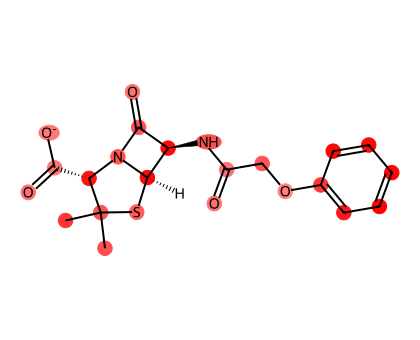

In [7]:
# paint the molecule: redder atom = more important to the prediction
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import io
mol = Chem.MolFromSmiles(mol_data.smiles)
colors = {i: (1.0, 1.0-float(atom_importance[i]), 1.0-float(atom_importance[i]))
          for i in range(mol.GetNumAtoms())}            # white -> red by importance
d = rdMolDraw2D.MolDraw2DCairo(420, 340)
rdMolDraw2D.PrepareAndDrawMolecule(
    d, mol, highlightAtoms=list(range(mol.GetNumAtoms())), highlightAtomColors=colors)
d.FinishDrawing()
img = Image.open(io.BytesIO(d.GetDrawingText()))

order = np.argsort(atom_importance)[::-1][:5]
print("Most influential atoms (index : element : importance):")
for i in order:
    print(f"  {i:2d} : {mol.GetAtomWithIdx(int(i)).GetSymbol():2s} : {atom_importance[i]:.2f}")
img                                                     # displays inline (redder = more important)

## D. Where to go next

You've built the core. The research frontier extends it along four axes:

**1. Richer graphs — use the bonds.** We only used atom features. Bonds carry type (single/double/aromatic) and stereochemistry. `edge_attr` + layers that consume it (e.g. `NNConv`, `GINEConv`, or a full **Message Passing Neural Network / MPNN**) typically lift BBBP AUC several points.

**2. 3D / geometric GNNs.** A molecule's behaviour depends on its 3D shape, not just connectivity. **SchNet, DimeNet, EGNN** operate on atomic *coordinates* and respect rotational symmetry — the standard for property and binding prediction.

**3. Pretraining.** Labelled medical data is scarce. Self-supervised pretraining on millions of unlabelled molecules (**MolCLR, GROVER, Grover, ChemBERTa**) then fine-tuning on BBBP is the modern recipe — the same transfer-learning story as in NLP.

**4. Other medical graph tasks** — the same machinery, different graph:
- **Drug–drug interaction** → *link prediction* on a drug graph.
- **Protein function / binding** → GNNs on residue-contact graphs (AlphaFold-style inputs).
- **Patient diagnosis** → *node classification* on patient-similarity or knowledge graphs.
- **Molecular generation** → graph generative models (JT-VAE, GFlowNets) for drug design.

**Tooling to know:** **PyTorch Geometric** (used here) and **DGL** are the two major libraries; **DeepChem** wraps molecular ML end-to-end; **Open Graph Benchmark (OGB)** provides standard datasets and leaderboards including `ogbg-molhiv`/`ogbg-molpcba`.

---

### The whole series in one breath
You represented a molecule as a graph (**01**), derived message passing and built a GCN layer by hand (**02**), assembled a full from-scratch classifier with batching, pooling, and training (**03**), rebuilt it in PyTorch Geometric and saw each hand-written piece become one call (**04**), and reached attention, expressiveness, honest scaffold evaluation, and explainability (**05**). That's the path from first principles to practitioner. Go pick one axis above and push it.